# Principal components analysis

Suppose we conduct an experiment $n$ times and collect $p$ pieces of information from each experiment. Then we can suppose that we collected a dataset $\mathcal{D} = \{ (x_{11},x_{12},\cdots, x_{1p} ), (x_{21},x_{22},\cdots, x_{2p} ),  \cdots, (x_{n1},x_{n2},\cdots, x_{np} )  \}$ and can organize this dataset into the following dataframe 

\begin{align}
    \mathcal{F} = \begin{bmatrix}
        x_{11} & x_{12} & \cdots & x_{1p}\\
        x_{21} & x_{22} & \cdots & x_{2p}\\
        \vdots & \vdots & \vdots & \ddots \\
        x_{n1} & x_{n2} & \cdots & x_{np}\\
        \end{bmatrix}
\end{align}

It is important to acknowledge that a single observation is the tuple $(x_{i1} \cdots x_{1p})$ and so we assume that a tuple of random variables *jointly* generated this single observation. 
In other words, it may not be appropriate to treat each piece of information (often called a covariate) as being generated independently of other covariates: they are generated together.   

The goal of principal components analysis is to find combinations of covariates that "best" describe our original dataset $\mathcal{D}$. 

In this lesson we will aim to understand:
1. How principal components defines "best"
2. The interplay between the (linear) algebra and geometry of principal components
3. How to interpret the outputs of out principal components analysis
4. How principal components analysis differs from linear regression 

## Simulated data 

We will first build a simulated dataset to illustrate the main concepts in principal components analysis. Let the random variables $[X_{1}, X_{2}]$ have a multivariate normal distribution (MVN)

\begin{align}
    &\begin{bmatrix}
        X_{1} \\ 
        X_{2}
    \end{bmatrix} \sim \text{MVN}( \mu, \Sigma ) \\ 
    & \mu    = \begin{bmatrix} -1 \\ 1 \end{bmatrix} ; \; 
    \Sigma  = \begin{bmatrix} 1 & 0.3 \\ 0.3 & 2 \end{bmatrix}
\end{align}

As a recap, the vector $\mu$ decribes the expected value for $X_{1}$ (the value -1) and the expected value for $X_{2}$ (the value 1). 
The *covariance matrix* $\Sigma$ describes the variance for $X_{1}$ (the value 1), the variance for $X_{2}$ (the value 2), and the covariance between $X_{1}$ and $X_{2}$ (the value 0.3).  

We can use `numpy` to  help use generate $n=100$ observations from the above MVN where every observation contains two pieces of information (i.e. two covariates). 
In addition to storing our dataset, we will visualize this information by scatterplotting values of the first covariate versus values of the second covariate. 

### Plotting and centering our data 

Below, you will see two plots side-by-side. 
The first plot includes the scatter (blue circles) as well as a vertical and horizontal line at the values 0 (dashed blue lines). 
Though we typically draw the horizontal and vertical axes for a plot at 0, the value zero is 
arbitrary.
A more reasonable place to draw our axes may be the expected values for the first (-1) and second (1) covariate. We drew those axes as solid blue lines.  

The solid blue lines (expected values) look to be better centered over our dataset than the dashed lines (zeros). 

The above is the motivation behind **centering**. 
Instead of plotting our raw data $\mathcal{D} = \{ (x_{11}, x_{12}),(x_{21}, x_{22}),\cdots, (x_{n1}, x_{n2})  \}$ we can plot a centered dataset that describes the distance of each observation from their expected value or $(x_{i1} - \mu_{1}, x_{i2}-\mu_{2})$ for all $i$ observations. 
Another way to look at this is with our dataframe

\begin{align}
    \underset{-}{\mathcal{F}} = \begin{bmatrix}
        x_{11} - \mu_{1} & x_{12} - \mu_{2} \\
        x_{21} - \mu_{1} & x_{22} - \mu_{2} \\
        \vdots & \vdots \\
        x_{n1}- \mu_{1} & x_{n2} - \mu_{2} \\
        \end{bmatrix} = \mathcal{F}_{n \times 2} - \mu_{1 \times 2} 
\end{align}

Importantly, the original dataset describes the distance of each covariate from the (arbitrary) value zero. In other words, 

\begin{align}
    \mathcal{F} = \begin{bmatrix}
        x_{11}  & x_{12}  \\
        x_{21}  & x_{22}  \\
        \vdots & \vdots \\
        x_{n1} & x_{n2}  \\
        \end{bmatrix} =  \begin{bmatrix}
        x_{11} - 0 & x_{12} - 0 \\
        x_{21} - 0 & x_{22} - 0 \\
        \vdots & \vdots \\
        x_{n1}- 0 & x_{n2} - 0 \\
        \end{bmatrix} = \mathcal{F}_{n \times 2} - 0_{1 \times 2} 
\end{align}

The rightmost panel in our figure below plots the centered dataset (solid blue circles) as well as vertical and horizontal axes at zero. 
The reason that these horizonal/vertical lines at zero are centered over the data now is because the value zero for our *centered* dataset represents the expected value. 
For example, the $i^{\text{th}}$ observation is $(x_{1}= x_{i1}-\mu_{1}, x_{2} = x_{i1}-\mu_{2} )$. When $x_{1}=0$ then $x_{i1}-\mu_{1}=0$ or $x_{i1}=\mu_{1}$.
The same argument could be used for the second covariate as well. 
The centered datset describes *the distance from each covariate's expected value*. 

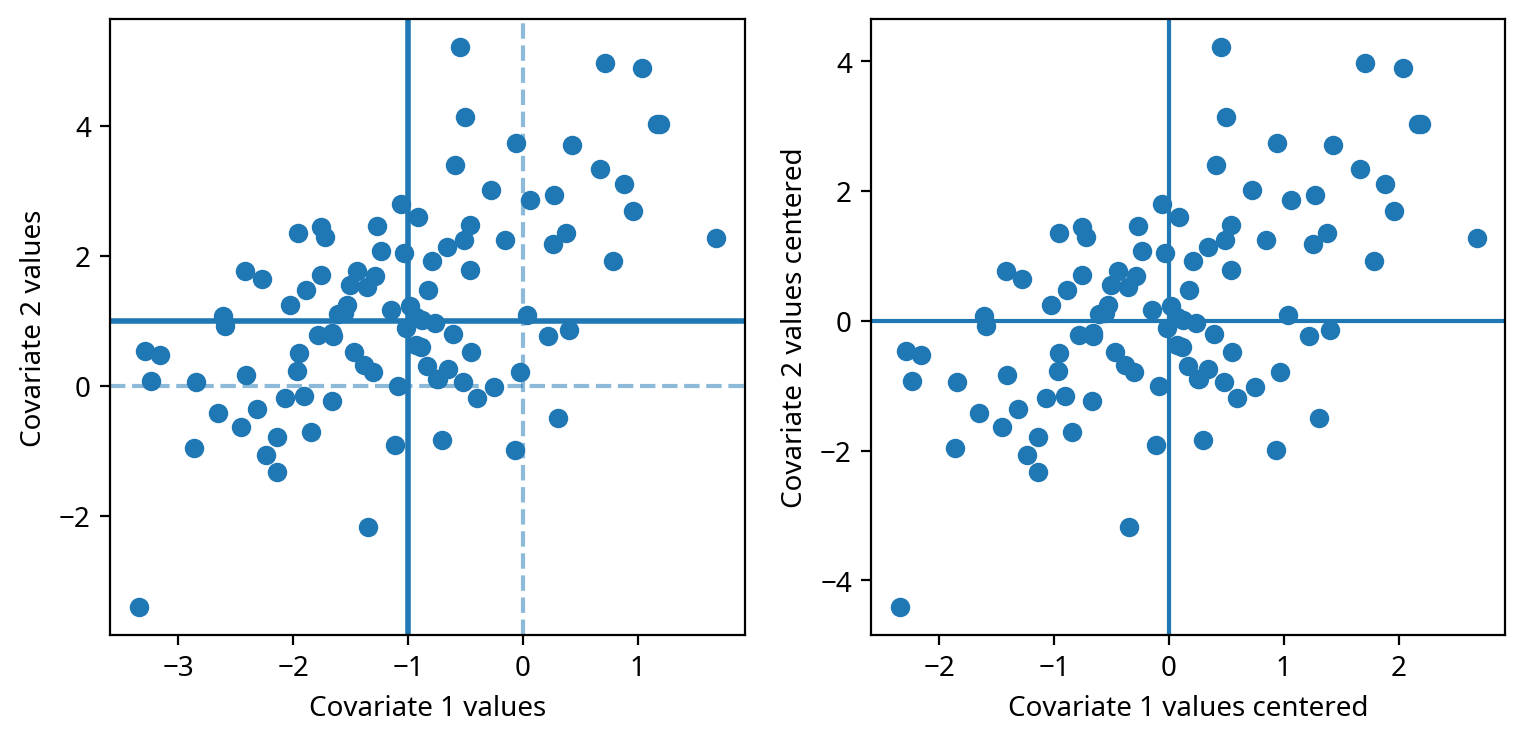

In [47]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

#--Specify the MVN expected value M and the covariance COV
#--Generate 100 observations from this vector of random variables  
M   = np.array([-1,1]) 
COV = np.array([[ 1, 0.6 ], [0.6 , 3]])

#--Note: these three lines are not important to know. 
#--You can just assume that this is the process by which we generate MVN observations. 
L   = np.linalg.cholesky(COV)
z   = np.random.normal( 0,1 ,size = (100,2) )
d   = M + z@L


#--Visualize this dataset 
fig,axs = plt.subplots(1,2)

#--non-centered dataset
ax=axs[0]
ax.scatter(d[:,0], d[:,1])

ax.axhline(0, alpha=0.5, ls="--")
ax.axvline(0, alpha=0.5, ls="--")

ax.axhline(1,lw=2)
ax.axvline(-1,lw=2)

ax.set_xlabel("Covariate 1 values")
ax.set_ylabel("Covariate 2 values")

#--centered dataset
d_centered = d - M #<--subtract the expected value from each covariate

ax=axs[1]

ax.scatter(d_centered[:,0], d_centered[:,1])

ax.axhline(0)
ax.axvline(0)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")

fig.set_size_inches(9,4)

plt.show()

## Geometric intuition behind Principal Components Analysis

Centering our dataset (right panel above) helped us more naturally descirbe our dataset. 
The zero horizonal/vertical values now correspond to the expected value for the first/second covariate. 
However, centering only allows us to **shift** our axes up/down and left/right to better decribe our data. 
What about rotation?

Geometrically, Principal Components Analysis asks "Can we rotate our axes to better characterize our dataset?". Well, if we are willing to consider rotating our axes then we need to decide on what we mean when say better. 

Lets start with just the horizontal axis and no vertical axis. 

Below is a short video that shows several iterations of the following steps:
1. (Top left) Produce a scatter plot of $x_{1}$ on the horizonal axis and $x_{2}$ on the vertical axis.
2. (Top right) Include only the horizontal axis and project all of the points onto this axis. To be clear, this projection maps every data point $(x_{1},x_{2}) \to x_{1}$. 
3. (Bottom left) Plot a histogram of the projected points. In other words, produce a histogram of the $x_{1}$ values and include a red shaded region that charazterizing 95\% probability. From this sample of $x_{1}$ points we will compute the variance or $\text{Var}(x_{1},x_{2},\cdots,x_{n})$. This value is titled at the top of the plot. 
4. (Bottom right) Append this variance value to a list of all the variances, one for each iteration, and plot a histogram of these variances.

Its important here to note what objects are random and which are not. 
We can see in this video os simultions that *randomness* does **not** come from the projection (our choise of the horizontal axis). Over each iteration the horizontal axis never changes. 
Instead, the randomness comes from our sample of data points. 

In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# --------------------------------------------------
# Parameters
# --------------------------------------------------

M   = np.array([-1,1])
COV = np.array([[1,0.6],[0.6,2]])

variances = []

fig,axs = plt.subplots(2,2, figsize=(6,6))
fig.tight_layout()

# --------------------------------------------------
# Animation frame
# --------------------------------------------------

def animate(frame):

    global variances

    # clear axes
    for ax in axs.ravel():
        ax.clear()

    # -------------------------
    # sample new dataset
    # -------------------------

    L = np.linalg.cholesky(COV)

    z = np.random.normal(
        0,1,
        size=(100,2)
    )

    d = M + z @ L.T

    d_centered = d - M

    var = np.var(d_centered[:,0])
    variances.append(var)

    # -------------------------
    # panel 1
    # -------------------------

    ax = axs[0,0]

    ax.scatter(
        d_centered[:,0],
        d_centered[:,1]
    )

    ax.axhline(0)
    ax.axvline(0,ls="--",alpha=0.4)

    ax.set_xlim(-5,5)
    ax.set_ylim(-5,5)

    ax.set_title(
        f"Dataset #{frame+1}"
    )

    # -------------------------
    # panel 2
    # -------------------------

    ax = axs[0,1]

    ax.scatter(
        d_centered[:,0],
        d_centered[:,1]
    )

    ax.axhline(0,color="black")

    ax.vlines(
        x=d_centered[:,0],
        ymin=0,
        ymax=d_centered[:,1],
        alpha=0.2
    )
    ax.set_xlim(-5,5)
    ax.set_ylim(-5,5)


    # -------------------------
    # panel 3
    # -------------------------

    ax = axs[1,0]

    x = d_centered[:,0]
    var = np.var(x, ddof=1)
    sd  = np.sqrt(var)

    ci_low  = -1.96 * sd
    ci_high =  1.96 * sd

    sns.histplot(
        x=x,
        bins=15,
        ax=ax
    )

    ax.axvspan(
        ci_low,
        ci_high,
        color="red",
        alpha=0.20
    )

    ax.axvline(ci_low, color="red", linestyle="--")
    ax.axvline(ci_high, color="red", linestyle="--")

    ax.set_xlim(-5,5)
    ax.set_title(
        f"Sample variance={var:.2f}"
    )

    # -------------------------
    # panel 4
    # -------------------------

    ax = axs[1,1]

    sns.histplot(
        x=variances,
        bins=20,
        ax=ax
    )

    # red dot showing the newest variance estimate
    ax.scatter(
        var,
        0,
        color="red",
        s=50,
        zorder=5
    )
    ax.scatter(
        np.mean(variances),
        0.25,
        color="red",
        s=50,
        marker="x",
        zorder=5
    )

    ax.set_title(
        f"{len(variances)} variance estimates"
    )
# --------------------------------------------------
# Create movie
# --------------------------------------------------

ani = FuncAnimation(
    fig,
    animate,
    frames=100,
    interval=500
)

plt.close(fig)

HTML(ani.to_jshtml())

Now that we see how to map a projection of $x$ onto the horizontal axis, it is intuitive that we might want to consider projections onto more complicated directions than just the horizontal (or vertical for that matter) projection.    

### A projection of one vector $x$ onto another direction $u$

Suppose we have a vector $x$ (in red) and want to project this vector onto another called $u$ (in blue). See the picture below. 
Then we know that this projection, called $x_{u}$ must be in the same direction as $u$.
We can write this down mathemtically as 

\begin{align}
    x_{u} = \alpha u
\end{align}

where $\alpha$ defines how far in the direction of $u$ we should move. 
But, we are not sure how far in the direction of $u$ we should extend this vector to be considered a "projection" of $x$ onto $u$. 

One reasonable property we might suggest for our projection $x_{u}$, is that this vector will be in the direction of $u$ and as close as possible to our original $x$.
The vector that is closest to $x$ but in the direction of $u$ is the on such that $x-u$ and $u$ are orthogonal to one another (instead or orthogonal, perpendicular is ok to use here as well). 

To see why, intuitively, we plotted the difference between two projections onto u. 
The first difference we plotted as a black dashed line that is perpendicular to $u$.
The second difference, drawn as a purple dashed-dot line is not perpendicular to $u$.
You can see that the line that is perpendicular to $u$ is shorter in length than the other. 

We can also see why this is the case algebraically by looking at the distance between $x$ and the projection of $x$ onto $u$ or $x_{u}$.
The typical way to define the length of a vector is 

\begin{align}
    ||x||     & = (x^{T}x)^{1/2}. \\ 
\end{align}

It is important to note that if the length of $x$ is smallest than the squared length is smallest too. The squared length is almost always better to work with because 

\begin{align}
    ||x||^{2} & = (x^{T}x)
\end{align}

In other words, we want to find the value $\alpha$ that minimizes 

\begin{align}
    ||x - x_{u}||^{2} = ||x - \alpha u||^{2} & = (x-\alpha u)^{T} (x-\alpha u) \\
                      &= x^{T}x - 2\alpha x^{T} u + \alpha^{2} u^{T}u
\end{align}

Lets take the derivative and set this to zero to find that 

\begin{align}
    f(\alpha) &= x^{T}x - 2\alpha x^{t} u + \alpha^{2} u^{T}u\\
    \frac{df}{d \alpha} = - 2 x^{T} u + 2 \alpha u^{T}u = 0 
    \alpha = \frac{x^{T} u }{ u^{T} u }
\end{align}

Now when we look at the vector $u$ and the residual $(x - \alpha u)$ we see that 

\begin{align}
    u^{T}  \left ( x - \frac{x^{T} u }{ u^{T} u } u  \right) &= 
    u^{T} x - \frac{x^{T} u}{u^{T} u} u^{T} u  \\ 
    &= u^{T} x - x^{T} u = 0
\end{align}

**There is an important lesson here**. 
When we want to choose a vector in the direction of $u$ such that it is closest to $x$ then the vector that we need to choose is one such that $u$ and the residual, $(x-\alpha u)$, are orthogonal. 




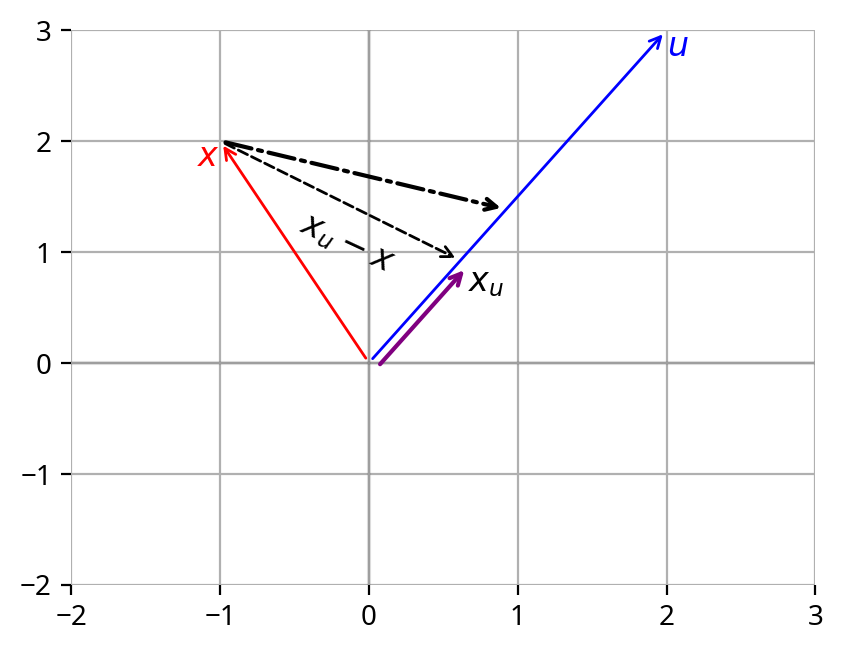

In [49]:
import matplotlib.pyplot as plt 
import numpy as np 

fig, ax = plt.subplots()

ax.axhline(0,alpha=0.10,color="k")
ax.axvline(0,alpha=0.10,color="k")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.grid()

x = np.array([-1,2])
u = np.array([2,3])

ax.annotate('', 
            xy=( x[0], x[1]),             # Point the arrow points to
            xytext=(0,0),         # Where the arrow starts (tail)
            arrowprops=dict(arrowstyle="->", color="red", lw=1.,ls="-"))
ax.text(x[0],x[1],s= r"$x$",fontsize=12,ha="right",va="top",color="red")


ax.annotate('', 
            xy=( u[0], u[1]),             # Point the arrow points to
            xytext=(0,0),         # Where the arrow starts (tail)
            arrowprops=dict(arrowstyle="->", color="blue", lw=1.,ls="-"))
ax.text(u[0],u[1],s= r"$u$",fontsize=12,ha="left",va="top",color="blue")


ax.text(-0.5,.75, rotation=-25,s= r"$x_{u}-x$",fontsize=12,ha="left",va="bottom",color="black")


alpha = (x.T @ u) / (u.T@u)
proj = alpha*u

ax.annotate('', 
            xy=( proj[0], proj[1]),             # Point the arrow points to
            xytext=(x[0], x[1]),         # Where the arrow starts (tail)
            arrowprops=dict(arrowstyle="->", color="black", lw=1.,ls="--"))

eps=0.05
ax.annotate('', 
            xy=( proj[0]+eps, proj[1]-eps),             # Point the arrow points to
            xytext=(0+eps, 0-eps),         # Where the arrow starts (tail)
            arrowprops=dict(arrowstyle="->", color="purple", lw=1.5))
ax.text(proj[0]+eps, proj[1]-eps,s= r"$x_{u}$",fontsize=12,ha="left",va="top")

#--alternative projection 
alpha = 1.5*alpha
alt_u = alpha*u

ax.annotate('', 
            xy=( alt_u[0], alt_u[1]),             # Point the arrow points to
            xytext=( x[0], x[1]),         # Where the arrow starts (tail)
            arrowprops=dict(arrowstyle="->", color="black", lw=1.5,ls="-."))


ax.set_xlim(-2,3)
ax.set_ylim(-2,3)

plt.show()

**Recap**
If i want to project the vector $x$ onto (or in the direction of) the vector $u$ then that projection is 

\begin{align}
    x_{u} = \frac{ x^{T}u }{u^{T}u} u = \frac{ u^{T}x }{u^{T}u} u
\end{align}

We can also extend this idea to project **many vectors** onto the vector $u$. 
For example, suppose that we have three vectors: $x_{1}$,$x_{2}$, and $x_{3}$ and wish to project them all onto $u$. Then we can form the following matrix multiplication to do this in one swoop.

its important to note below that we need to divide the vector $u$ by $u^{T}u$

Let $\tilde{u} = \frac{u}{u^{T}u}$ then 

\begin{align}
    X \tilde{u} = \frac{Xu}{u^{T}u} =      \begin{bmatrix}
        x_{1}^{T} u \Big / u^{T}u \\
        x_{2}^{T} u \Big / u^{T}u \\
        \vdots \\ 
        x_{n}^{T} u \Big / u^{T}u \\
        \end{bmatrix} = \begin{bmatrix} 
        \alpha_{1} \\ 
        \alpha_{2} \\
        \vdots\\
        \alpha_{n} \\ 
        \end{bmatrix}
\end{align}

## Projecting onto different directions

Back to our data as a stacked matrix of vectors or 

\begin{align}
 X = \begin{bmatrix}
        \rule[0.5ex]{1.2em}{0.4pt} x_{1} \rule[0.5ex]{1.2em}{0.4pt}  \\
        \rule[0.5ex]{1.2em}{0.4pt} x_{2} \rule[0.5ex]{1.2em}{0.4pt}\\
        \vdots \\ 
        \rule[0.5ex]{1.2em}{0.4pt} x_{n} \rule[0.5ex]{1.2em}{0.4pt}\\
   \end{bmatrix}
\end{align}

Given a direction vector, $u$, we can project our data onto this $u$ by first computing 
$\tilde{u} = u / (u^{T}u)$ and and then computing $ X_{u} = X u$. 
The notation $X_{u}$ stands for the vectors $x_{1}, x_{2}, \cdots, x_{n}$ projected in the direction of $u$. 

Lets see how this works for the horizontal and vertical axes. 
The horizontal axis is in the direction $u = [1,0]$, and we see that $u^{T}u = [1,0]^{T}[1,0] = 1^{2} + 0^{2} = 1$ and so we can project our data onto the horizontal axis by computing 

\begin{align}
    X_{ [1,0] } &= X \begin{bmatrix} 1 \\ 0 \end{bmatrix} \\ 
    &= \begin{bmatrix} 
        x_{11} & x_{12} \\ 
        x_{21} & x_{12} \\ 
        \vdots & \vdots \\ 
        x_{n1} & x_{n2} \\ 
        \end{bmatrix}\begin{bmatrix} 1 \\ 0 \end{bmatrix} 
    = \begin{bmatrix}
        x_{11} \\ 
        x_{21} \\ 
        \vdots\\
        x_{n1} \\ 
      \end{bmatrix}
\end{align}

In other words "projecting" onto the horizontal axis is just selecting the first entry in each vector. In this 2-dimensional example, we can also project onto the vertical axis by choosing the direction vector $u = [0,1]^{T}$, and so then 

\begin{align}
    X_{ [0,1] }
= \begin{bmatrix}
        x_{12} \\ 
        x_{22} \\ 
        \vdots\\
        x_{n2} \\ 
      \end{bmatrix}
\end{align}

Below we will project our data, $X$, onto three different $u$ vectors: (Top right) $u=[1,0]^{T}$, (Bottom Left) $u = [1,-1]^{T}$, and (Bottom Right) $u=[1,1]^{T}$. The panel on the Top Left shows the typical visualization of our data not projected onto a $u$ vector. 


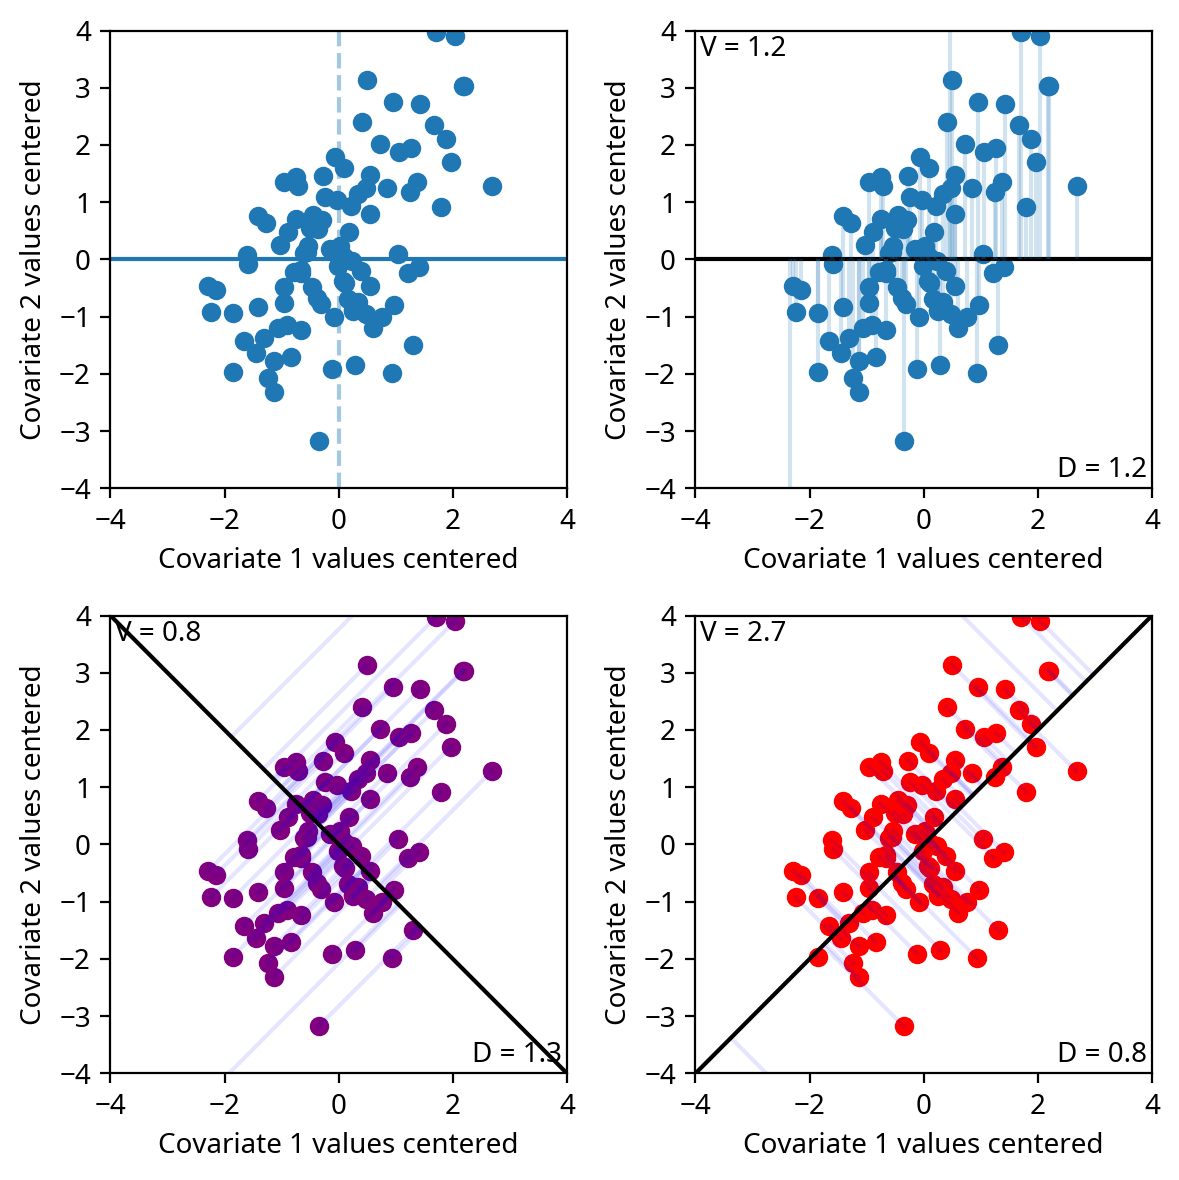

In [50]:

import numpy as np 
import matplotlib.pyplot as plt 
fig,axs = plt.subplots(2,2)

ax=axs[0,0]
ax.scatter(d_centered[:,0], d_centered[:,1])

ax.axhline(0)
ax.axvline(0,ls="--",alpha=0.4)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")
ax.set_xlim(-5,5)
ax.set_ylim(-5,5)


ax=axs[0,1]

ax.scatter(d_centered[:,0], d_centered[:,1])
ax.axhline(0,color="black")
ax.vlines(x=d_centered[:,0], ymin=0, ymax=d_centered[:,1],alpha=0.2)

u = np.array([1,0]).reshape(2,1)
alphas = d_centered @ u
var    = np.var(alphas)

dist   = d_centered - alphas@u.T
dist   = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)

ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)



ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")
ax.set_xlim(-5,5)
ax.set_ylim(-5,5)


ax=axs[1,0]
u      = np.array([-1,1]).reshape(2,1)
u      = u/np.linalg.norm(u)

alphas = (d_centered @ u) #<-- N X 1

var    = np.var(alphas)

dist   = d_centered - alphas@u.T
dist   = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)


for point,alpha in zip(d_centered, alphas):
    alpha = float(alpha[0])
    u0    = float(u[0,0])
    u1    = float(u[1,0])
    ax.plot( [alpha*u0, point[0] ] ,  [alpha*u1, point[1]  ], color="blue", alpha=0.1  )
    ax.scatter( point[0], point[1], color ="purple" )
    
ax.plot( [-4,4], [4,-4], color="black" )  
ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")
ax.set_xlim(-5,5)
ax.set_ylim(-5,5)

ax=axs[1,1]
u      = np.array([1,1]).reshape(2,1)
u      = u/np.linalg.norm(u)

alphas = (d_centered @ u) #<-- N X 1

var    = np.var(alphas)

dist   = d_centered - alphas@u.T
dist   = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)

for point,alpha in zip(d_centered, alphas):
    alpha = float(alpha[0])
    u0    = float(u[0,0])
    u1    = float(u[1,0])
    ax.plot( [alpha*u0, point[0] ] ,  [alpha*u1, point[1]  ], color="blue", alpha=0.1  )
    ax.scatter( point[0], point[1], color ="red" )
    
ax.plot( [-4,4], [-4,4], color="black" )  
ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)

ax.set_xlim(-5,5)
ax.set_ylim(-5,5)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")

fig.set_tight_layout(True)
fig.set_size_inches(6,6)

plt.show()

## The numerical solve for picking the best u

We now know that we can project all of our vector observations onto a new axis (also a vector) $u$ by computing 

\begin{align}
    \alpha^{u} = X \frac{u}{|| u || }
\end{align}

The "weights" $\alpha^{u}$ are those weights that you would apply to $u$ to obtain the projected data point $\alpha_{i}^{u} \frac{u}{||u||}$ that is closest to your $i^{\text{th}}$ data point. 

Now shift focus to $u$. 
Is there an optimal, or a best, $u$? 
If you want to find an optimal anything then you need to define a metric by which to measure best. 

A common option in statistics is to pick the mean squared error. Let $u$ be a normalized vector $||u||=1$ of dimension $k \times 1$ and our data matrix $X$ be dimension $n \times k$.
Then  

\begin{align}
    \text{MSE}(u) &= \frac{1}{N} \sum_{i=1}^{N} || x_{i,:} - \alpha^{u}_{i} u' ||^{2} \\
\end{align}

In [51]:
from scipy.optimize import minimize #<-- This helps us pick the u with smallest MSE

def objective_function(X,u):
    #--X is nXk and u is kX1
    n,k = X.shape
    u = u.reshape(k,1)
    
    #--make sure that the u vector is normalized 
    unorm = np.linalg.norm(u)
    u     = u/unorm 
    
    #--project X observations onto u 
    alpha = X @ u #--This is nX1
    
    #--compute MSE and retrun it 
    mse = np.linalg.trace(  (X - alpha*u.T).T @ (X - alpha*u.T) )  / n
    
    return mse 

X = d_centered
n,k = X.shape 

random_start = np.random.random( k ) #<--pick a random u to start 
results = minimize( lambda u: objective_function(X,u), x0 = random_start )
results

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 0.6966306956981749
        x: [ 4.197e-02  7.674e-02]
      nit: 8
      jac: [ 9.298e-06 -2.258e-06]
 hess_inv: [[ 1.616e-03  3.490e-03]
            [ 3.490e-03  1.481e-02]]
     nfev: 36
     njev: 12

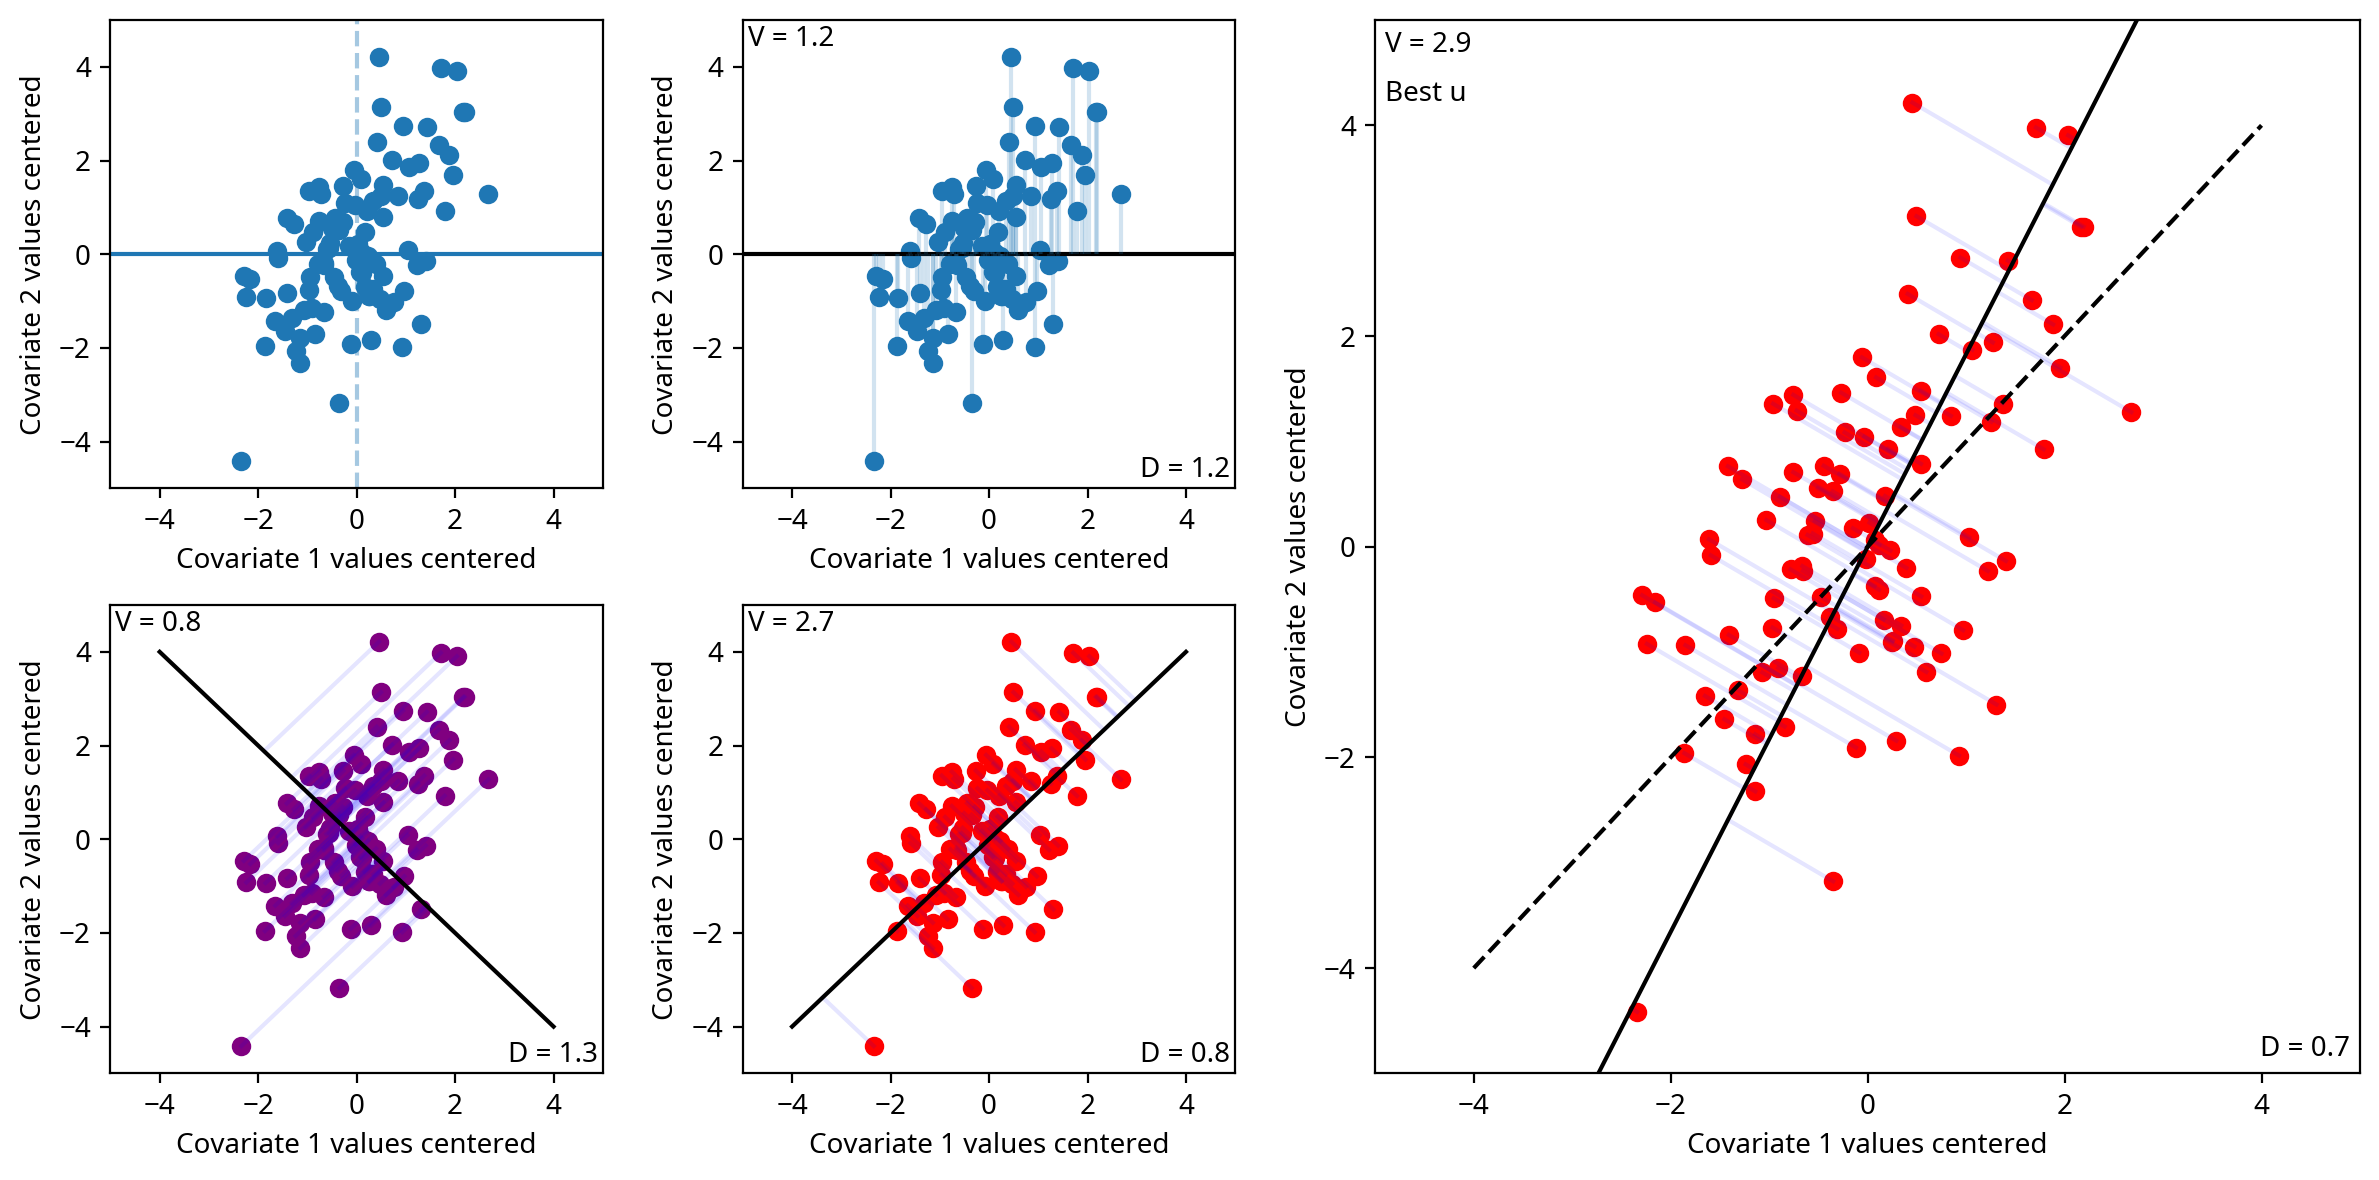

In [64]:
from matplotlib.gridspec import GridSpec
import numpy as np 
import matplotlib.pyplot as plt 

fig = plt.figure()

gs = GridSpec(2, 3, width_ratios=[1,1 ,2], height_ratios=[1, 1])

ax = fig.add_subplot(gs[0,0])
ax.scatter(d_centered[:,0], d_centered[:,1])

ax.axhline(0)
ax.axvline(0,ls="--",alpha=0.4)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")
ax.set_xlim(-5,5)
ax.set_ylim(-5,5)


ax = fig.add_subplot(gs[0,1])

ax.scatter(d_centered[:,0], d_centered[:,1])
ax.axhline(0,color="black")
ax.vlines(x=d_centered[:,0], ymin=0, ymax=d_centered[:,1],alpha=0.2)

u = np.array([1,0]).reshape(2,1)
alphas = d_centered @ u
var    = np.var(alphas)

dist   = d_centered - alphas@u.T
dist   = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)

ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)



ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")
ax.set_xlim(-5,5)
ax.set_ylim(-5,5)

ax = fig.add_subplot(gs[1,0])

u      = np.array([-1,1]).reshape(2,1)
u      = u/np.linalg.norm(u)

alphas = (d_centered @ u) #<-- N X 1

var    = np.var(alphas)

dist   = d_centered - alphas@u.T
dist   = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)


for point,alpha in zip(d_centered, alphas):
    alpha = float(alpha[0])
    u0    = float(u[0,0])
    u1    = float(u[1,0])
    ax.plot( [alpha*u0, point[0] ] ,  [alpha*u1, point[1]  ], color="blue", alpha=0.1  )
    ax.scatter( point[0], point[1], color ="purple" )
    
ax.plot( [-4,4], [4,-4], color="black" )  
ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")
ax.set_xlim(-5,5)
ax.set_ylim(-5,5)

ax = fig.add_subplot(gs[1,1])

u      = np.array([1,1]).reshape(2,1)
u      = u/np.linalg.norm(u)

alphas = (d_centered @ u) #<-- N X 1

var    = np.var(alphas)

dist   = d_centered - alphas@u.T
dist   = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)

for point,alpha in zip(d_centered, alphas):
    alpha = float(alpha[0])
    u0    = float(u[0,0])
    u1    = float(u[1,0])
    ax.plot( [alpha*u0, point[0] ] ,  [alpha*u1, point[1]  ], color="blue", alpha=0.1  )
    ax.scatter( point[0], point[1], color ="red" )
    
ax.plot( [-4,4], [-4,4], color="black" )  
ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)

ax.set_xlim(-5,5)
ax.set_ylim(-5,5)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")

fig.set_tight_layout(True)
fig.set_size_inches(6,6)


ax = fig.add_subplot(gs[:,2])


u = results.x.reshape(k,1) 
u = u/np.linalg.norm(u)

alphas = (d_centered @ u) #<-- N X 1

var    = np.var(alphas)

dist     = d_centered - alphas@u.T
dist     = np.linalg.norm(dist,axis=1)
avg_dist = np.mean(dist)

for point,alpha in zip(d_centered, alphas):
    alpha = float(alpha[0])
    
    u0    = float(u[0,0])
    u1    = float(u[1,0])
    
    ax.plot( [alpha*u0, point[0] ] ,  [alpha*u1, point[1]  ], color="blue", alpha=0.1  )
    ax.scatter( point[0], point[1], color ="red" )
    
ax.plot( [-4, 4 ], [ -4*u[1]/u[0], 4*u[1]/u[0]]   , color="black" )  
ax.plot( [-4, 4 ], [ -4, 4]   , color="black", ls="--" )  

ax.text(0.01,0.99,s="V = {:.1f}".format(var),ha="left",va="top",transform=ax.transAxes)
ax.text(0.99,0.01,s="D = {:.1f}".format(avg_dist),ha="right",va="bottom",transform=ax.transAxes)

ax.set_xlim(-5,5)
ax.set_ylim(-5,5)

ax.set_xlabel("Covariate 1 values centered")
ax.set_ylabel("Covariate 2 values centered")

ax.text( 0.01, 0.93, s="Best u", transform=ax.transAxes,ha="left",va="center" ) 

fig.set_tight_layout(True)
fig.set_size_inches(12,6)

plt.show()

### The theoretical solve for piclking the best (i.e. what does the best u imply?)

Lets go back to the MSE metric that we used to pick our best $u$ numerically. 
Instead of a general solver to pick our best $u$, lets instead use matrix algebnra to see if best $u$ takes a specific form or is a solution to a specirfic probem that might look familar to us (hint hint). 

First we start with MSE and rewrite our weights $\alpha_{i}$ in terms of the inner product with $x$ and $u$. 

\begin{align}
    \text{MSE}(u) &= \frac{1}{N} \sum_{i=1}^{N} || x_{i,:} - \alpha^{u}_{i} u' ||^{2} \\
           &= \frac{1}{N} \sum_{i=1}^{N} || x_{i,:} -  (x_{i,:} u)  u' ||^{2} \\
           &= \frac{1}{N} \sum_{i=1}^{N} (x_{i,:} -  (x_{i,:} u)  u') (x_{i,:} -  (x_{i,:} u)  u')' \\ 
\end{align}

Lets remember the dimensions of $u$ and $X$. 
$X$ is a matrix thats is $n \times k$: $n$ obsevrations where every observation contains $k$ units of information. 
Then $u$ is shape $k \times 1$. 

Looking at the above expression, we could just convert $x$ into the matrix $X$ and we actually get pretty close. 

\begin{align}
    (X - (X u)  u') (X - (X u)  u')'
\end{align}

The expression $(X_{n \times k} - (X_{n \times k} u_{k \times 1})  u'_{1 \times k})$ has dimenson $ {n \times k} $ and so then this expression times its transpose would be a matrix of $n \times n$! A matrix thats $n \times n$ is hardly a single value like the MSE. Lets look closer at what entry looks like, and we'll see we can extract and sum specific values from this matrix to compute the MSE.  

\begin{align}
    (X - (X u)  u') (X - (X u)  u')' = \begin{bmatrix}
        \left(x_{1,:} - (x_{1,:} u) u'\right)\left(x_{1,:} - (x_{1,:} u) u'\right) & \left(x_{1,:} - (x_{1,:} u) u'\right)\left(x_{2,:} - (x_{2,:} u) u'\right) & \cdots \\ 
        \left(x_{2,:} - (x_{2,:} u) u'\right)\left(x_{1,:} - (x_{1,:} u) u'\right) & \left(x_{2,:} - (x_{2,:} u) u'\right)\left(x_{2,:} - (x_{2,:} u) u'\right) & \cdots \\ 
        \vdots & \vdots & \vdots 
    \end{bmatrix}
\end{align}

If we look at the diagonal thwn we see that all the diagonal terms added up is exactly the MSE. Nice. 
This process shows up so often that there is a mathematical function for summing the diagaonal of a matrix: the trace (tr). 

This then means that the trace of $(X - (X u)  u') (X - (X u)  u')'$ will get us to our MSE.

\begin{align}
        MSE(u)  &= \frac{1}{N}   tr\left[  (X - (X u)  u') (X - (X u)  u')' \right] \\  
\end{align}


\begin{align}
           &= \frac{1}{N}   tr\left[  (X - (X u)  u') (X' - u u' X') \right] \\ 
           &= \frac{1}{N}   tr\left[  (X X' - X u u' X' - (X u)  u'X' + (X u)  u'u u' X')  \right] \\
           &= \frac{1}{N}   tr\left[  (X X' - X u u' X' - (X u)  u'X' + (X u) u' X')  \right] \hspace{1mm} (\text{we assume } u'u=1) \\
           &= \frac{1}{N}   tr (X X' - X u u' X') \\
\end{align}

There are two useful properties of the trace (that you can verify). 

\begin{align}
    tr(A + B) &=  tr(A) + tr(B) \\ 
    tr(ABC)   &= tr(CAB) & tr(BCA)\hspace{1mm} (\text{cyclic property of the trace})\\
\end{align}

Lets use these two properties to  further simplify our MSE

\begin{align}
    \text{MSE}(u) &= \frac{1}{N}  \left[   tr \left(X X'\right) - tr\left(X u u' X'\right) \right] \\
                  &= \frac{1}{N}  \left[   tr \left(X X'\right) - tr\left(u' X'X u \right) \right] \hspace{1mm} (\text{cyclic property of the trace}) \\
\end{align}

Our goal is to find the $u$ that minimizes the MSE. 
Well the first term doesnt depend on $u$ and so can be excluded. 
Then, if we want to minimize the MSE we want to find a u that minimizes 

\begin{align}
  \min_{u}  -\frac{1}{N} tr\left(u' X' X u \right) &= \frac{1}{N} u' X' X u \\ 
    &= -\frac{1}{N} u' \Sigma u \propto u' \Sigma u
\end{align}

where $\Sigma$ is called the covariance matrix for $X$. 
The $(i,j)$ element $\Sigma_{i,j}$ is the coviarance between random variables $X_{i}$ and $X_{j}$.
It is important to learn about the covariance matrix, especially in the context of the multivariate normal density.
You can begin learning about the multivariate normal and covariance matrix in the *nuts and bolts* section on the [Multivariate Normal](https://compuncertlab.org/courses/nuts_and_bolts/). 

Note that minimizing a negative quantity is equivalent to maximizing a positive quantity. 
This then means that we need to find the $u$ that maximizes 

\begin{align}
 f(u) = \max_{u} u' \Sigma u
\end{align}

where we chose to label this objective function $f$ to emphasize that the input is a vector $u$ and the output is $f(u)$. 

To enforce the constraint that $||u||^{2}=1$ we can us a lagrange multiplier. 

\begin{align}
 f(u,\lambda) = \max_{u} u' \Sigma u + \lambda (||u||^{2} -1)
\end{align}




In [53]:

l,u         = np.linalg.eigh(COV)
l_est,u_est = np.linalg.eigh( d_centered.T @ d_centered/N )



NameError: name 'N' is not defined

In [ ]:

u      = np.array([1,1]).reshape(2,1)
u      = u/np.linalg.norm(u)

alphas = (d_centered @ u) #<-- N X 1

fig, ax = plt.subplots()

for point,alpha in zip(d_centered, alphas):
    alpha = float(alpha)
    u0    = float(u[0])
    u1    = float(u[1])
    ax.plot( [alpha*u0, point[0] ] ,  [alpha*u1, point[1]  ], color="blue", alpha=0.1  )
    ax.scatter( point[0], point[1] )
    
ax.plot( [-3,3], [-3,3], color="black" )  

ax.set_aspect("equal")
ax.set_xlim(-3,3)
ax.set_ylim(-3,3)
plt.show()

In [ ]:
fig = plt.figure(figsize=(10, 5))
gs  = fig.add_gridspec(2, 3)

ax00 = fig.add_subplot(gs[0, 0])
ax10 = fig.add_subplot(gs[1, 0])

ax_proj = fig.add_subplot(gs[:, 1])  # joined second column
ax_box  = fig.add_subplot(gs[:, 2])  # joined third column

# ------------------------------------------------------------
# First row, first column: original data + projection to x-axis
# ------------------------------------------------------------
ax = ax00
ax.scatter(d_centered[:, 0], d_centered[:, 1])
ax.axhline(0, color="black", linewidth=1)
ax.vlines(x=d_centered[:, 0], ymin=0, ymax=d_centered[:, 1],colors="blue",alpha=0.2)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_title("Projection onto x-axis")

# ------------------------------------------------------------
# Second row, first column: original data + projection to u
# ------------------------------------------------------------
u = np.array([1, 1], dtype=float).reshape(2, 1)
u = u / np.linalg.norm(u)

alphas = d_centered @ u          # N x 1
projs  = alphas @ u.T            # N x 2

ax = ax10
for point, proj in zip(d_centered, projs):
    ax.plot([proj[0], point[0]],[proj[1], point[1]],color="blue",alpha=0.1,)
    ax.scatter(point[0], point[1])

ax.plot([-3, 3], [-3, 3], color="black")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_title(r"Projection onto u")

# ------------------------------------------------------------
# Joined second column: compare 1D projected coordinates
# ------------------------------------------------------------
x_proj = d_centered[:, 0]
u_proj = alphas.reshape(-1)

ax = ax_proj

ax.scatter(x_proj
           ,np.zeros_like(x_proj)
           ,facecolor="white",edgecolor="blue",alpha=0.5,label="x-axis")

ax.scatter(u_proj ,np.ones_like(u_proj) ,facecolor="white",edgecolor="darkorange",alpha=0.5,label="u")

ax.set_xlim(-4, 4)
ax.set_ylim(-1, 2)
ax.set_yticks([0, 1])
ax.set_yticklabels(["x-axis", r"$u$"])
ax.axvline(0, color="black", linewidth=1, alpha=0.4)
ax.set_xlabel("Projection coordinate")
ax.set_title("Projected points")

# ------------------------------------------------------------
projected_data = pd.DataFrame({
    "p": np.concatenate([x_proj, u_proj]),
    "projection": ( ["x-axis"] * len(x_proj) + ["u"] * len(u_proj) )})

ax = ax_box

sns.boxplot(x="p"
    ,y="projection"
    ,data=projected_data
    ,ax=ax
    ,width=0.35
    ,showcaps=True
    ,showfliers=False
    #,boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.5}
    #,whiskerprops={"color": "black", "linewidth": 1.2}
    #,capprops={"color": "black", "linewidth": 1.2}
    #,medianprops={"color": "black", "linewidth": 2}
)

sns.stripplot(x="p",y="projection",data=projected_data,ax=ax,jitter=0.18,size=4,alpha=0.55,color="black")

var_xaxis = np.var( x_proj )
var_proj  = np.var( u_proj )

ax.text( 0,1.25, s= "Var = {:.2f}".format(var_proj), va="bottom", ha="center" )
ax.text( 0,0.25, s= "Var = {:.2f}".format(var_xaxis), va="bottom", ha="center" )

ax.set_xlim(-4, 4)
ax.set_ylim(-1,2)
ax.set_xlabel("Projection coordinate")
ax.set_ylabel("")
ax.set_title("Summary of spread")

sns.despine(fig=fig)

plt.tight_layout()
plt.show()

In [ ]:
np.var( d_centered[:,0] ) 

In [ ]:
np.var(alphas)